# Course 2: Ten Years of Deep Learning Ideas
## Session 2: Optimizers, schedules and training at scale

**Goal:** compare Adam with L2 regularization against AdamW, test warmup and three learning-rate schedules, write Lion and Muon from scratch, and estimate the memory needed to train a large model.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup and data
Two small tasks. The first is scikit-learn's 8x8 digits with only 400 training images, so that regularization matters. The second is a synthetic 'language' introduced in section 4. Large-model training uses the same optimizers and schedules on billions of tokens; here every run takes a few seconds on a CPU.

In [1]:
import copy, math, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(2)          # tiny models run as fast on 2 threads, and shared machines stay responsive
torch.set_flush_denormal(True)
torch.manual_seed(0); np.random.seed(0)

digits = load_digits()
X_all = torch.tensor(digits.data, dtype=torch.float32)
y_all = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.5, random_state=0, stratify=y_all)
Xtr, ytr = Xtr[:400], ytr[:400]                      # a small training set
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-3
Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
print(f"digits: {len(Xtr)} training and {len(Xte)} test images")


def digits_mlp(seed=0, width=256):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(64, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, 10))


def train_digits(opt_class, lr=1e-3, weight_decay=0.0, warmup=0, steps=600, bs=64, seed=0):
    model = digits_mlp(seed)
    opt = opt_class(model.parameters(), lr=lr, weight_decay=weight_decay)
    g = torch.Generator().manual_seed(seed)
    for step in range(steps):
        for group in opt.param_groups:
            group["lr"] = lr * min(1.0, (step + 1) / warmup) if warmup else lr
        idx = torch.randint(len(Xtr), (bs,), generator=g)
        loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        acc = (model(Xte).argmax(1) == yte).float().mean().item()
        train_loss = F.cross_entropy(model(Xtr), ytr).item()
        weight_norm = math.sqrt(sum(p.pow(2).sum().item() for n, p in model.named_parameters() if "weight" in n))
    return acc, train_loss, weight_norm

digits: 400 training and 899 test images


### 2. L2 regularization is not weight decay under Adam
With plain SGD, adding (λ/2)‖w‖² to the loss adds λw to the gradient, and the update w ← w − η(g + λw) = (1 − ηλ)w − ηg is exactly weight decay. Adam divides each coordinate's step by the square root of its running average of squared gradients, √v. With L2 the λw term is divided too, so a weight with large gradients is barely decayed, while a weight with no gradient is pushed to zero at full speed. AdamW (Loshchilov & Hutter 2019) applies the decay separately: w ← w − η(m̂/(√v̂ + ε) + λw), the same relative shrinkage for every weight.

First a two-weight toy: weight 0 gets a large, noisy gradient with mean zero; weight 1 gets no gradient from the data. Both start at 1. PyTorch's `Adam(weight_decay=λ)` is L2 regularization; `AdamW(weight_decay=λ)` is decoupled decay.

In [2]:
def decay_demo(opt_class, steps=500, lr=0.01, lam=0.1):
    torch.manual_seed(0)
    w = torch.ones(2, requires_grad=True)
    opt = opt_class([w], lr=lr, weight_decay=lam)
    for _ in range(steps):
        loss = torch.randn(()) * 10 * w[0]          # gradient of weight 0: noise with standard deviation 10
        opt.zero_grad(); loss.backward(); opt.step()
    return w.detach()

for name, cls in [("Adam + L2", torch.optim.Adam), ("AdamW", torch.optim.AdamW)]:
    w = decay_demo(cls)
    print(f"{name:9s} after 500 steps: weight with large gradients {w[0]:.3f}, weight with no gradient {w[1]:.3f}")
print(f"pure decay (1 - lr*lambda)^500 = {(1 - 0.01 * 0.1) ** 500:.3f}")

Adam + L2 after 500 steps: weight with large gradients 0.882, weight with no gradient 0.000
AdamW     after 500 steps: weight with large gradients 0.541, weight with no gradient 0.606
pure decay (1 - lr*lambda)^500 = 0.606


Now the same comparison on the digits network, at the **same nominal** decay values λ, for 600 steps with learning rate 1e-3.

no decay: test accuracy 0.940, weight norm 17.1
lambda    Adam+L2: accuracy  norm    AdamW: accuracy  norm


0.0001               0.949  15.3            0.940  17.1


0.001                0.960  10.2            0.940  17.1


0.01                 0.954   6.9            0.940  17.0


0.1                  0.908   4.6            0.940  16.4


1                    0.101   0.0            0.948  12.5


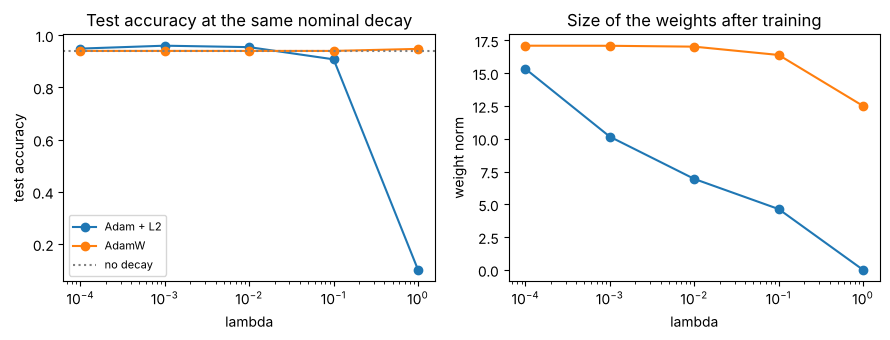

In [3]:
lams = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
base_acc, _, base_norm = train_digits(torch.optim.AdamW, weight_decay=0.0)
print(f"no decay: test accuracy {base_acc:.3f}, weight norm {base_norm:.1f}")
print("lambda    Adam+L2: accuracy  norm    AdamW: accuracy  norm")
wd_results = {}
for lam in lams:
    a = train_digits(torch.optim.Adam, weight_decay=lam)
    b = train_digits(torch.optim.AdamW, weight_decay=lam)
    wd_results[lam] = (a, b)
    print(f"{lam:<8g}  {a[0]:16.3f} {a[2]:5.1f}   {b[0]:14.3f} {b[2]:5.1f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for k, name in enumerate(["Adam + L2", "AdamW"]):
    ax[0].semilogx(lams, [wd_results[l][k][0] for l in lams], "o-", label=name)
    ax[1].semilogx(lams, [wd_results[l][k][2] for l in lams], "o-", label=name)
ax[0].axhline(base_acc, color="gray", ls=":", label="no decay")
ax[0].set(title="Test accuracy at the same nominal decay", xlabel="lambda", ylabel="test accuracy")
ax[1].set(title="Size of the weights after training", xlabel="lambda", ylabel="weight norm")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 3. Warmup at a high learning rate
At the start of training Adam's estimate of v comes from only a few gradients, so the first steps can be erratic; RAdam was designed around this (Liu et al. 2020). Large-batch SGD needed a gradual warmup for the same reason: early steps are too big for a network that has not settled yet (Goyal et al. 2017). We train the digits network with AdamW at three peak learning rates, with and without a linear warmup over the first 100 of 600 steps.

In [4]:
print("peak lr   no warmup: accuracy (train loss)   100-step warmup: accuracy (train loss)")
for lr in [0.01, 0.03, 0.1]:
    a = train_digits(torch.optim.AdamW, lr=lr, warmup=0)
    b = train_digits(torch.optim.AdamW, lr=lr, warmup=100)
    print(f"{lr:<8g}  {a[0]:19.3f} ({a[1]:.3f})        {b[0]:24.3f} ({b[1]:.3f})")

peak lr   no warmup: accuracy (train loss)   100-step warmup: accuracy (train loss)


0.01                    0.912 (0.000)                           0.919 (0.000)


0.03                    0.905 (0.000)                           0.932 (0.000)


0.1                     0.191 (1.939)                           0.555 (0.968)


### 4. Learning-rate schedules: constant, cosine and warmup-stable-decay
A synthetic language makes schedules easy to judge. There are 16 symbols, and the next symbol depends on the previous two through a fixed random table of probabilities. Because we know the table, we know the best possible loss (the entropy rate of the source), so we report the **excess loss**: the model's validation loss minus the best possible loss.

The model is a tiny 'language model': embeddings of the two previous symbols and an MLP of width 128. We compare, at a fixed budget of 1,500 AdamW steps with peak learning rate 3e-3 and 50 warmup steps:
- **constant**: stay at the peak;
- **cosine**: decay to zero along half a cosine wave (Loshchilov & Hutter 2017);
- **WSD (warmup-stable-decay)**: stay at the peak, then decay linearly to zero over the last 20% of steps (Hu et al. 2024; Hägele et al. 2024). Until step 1,200 it is the same run as 'constant', so the two curves overlap.

248000 training pairs; best possible loss 1.841 nats (uniform guessing: 2.773)


constant excess loss after 1500 steps: 0.1697


cosine   excess loss after 1500 steps: 0.1132


wsd      excess loss after 1500 steps: 0.1156


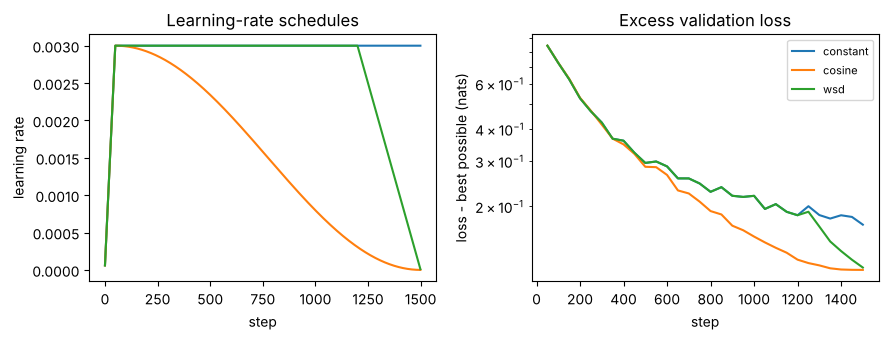

In [5]:
V, K = 16, 2
rng = np.random.default_rng(0)
P = rng.dirichlet(np.full(V, 0.3), size=V ** K)        # next-symbol probabilities for each of the 256 contexts
cum = P.cumsum(1)

def sample_sequences(n_seq, length, rng):
    s = np.zeros((n_seq, length), dtype=np.int64)
    s[:, :K] = rng.integers(0, V, (n_seq, K))
    for t in range(K, length):
        ctx = s[:, t - 2] * V + s[:, t - 1]
        s[:, t] = (cum[ctx] < rng.random(n_seq)[:, None]).sum(1).clip(max=V - 1)
    return s

def to_pairs(seq):
    ctx = np.stack([seq[:, :-2], seq[:, 1:-1]], -1).reshape(-1, 2)
    return torch.tensor(ctx), torch.tensor(seq[:, 2:].reshape(-1))

Ctr, Ytr = to_pairs(sample_sequences(4000, 64, rng))
Cva, Yva = to_pairs(sample_sequences(500, 64, np.random.default_rng(1)))
best_loss = -np.log(P[(Cva[:, 0] * V + Cva[:, 1]).numpy(), Yva.numpy()]).mean()
print(f"{len(Ytr)} training pairs; best possible loss {best_loss:.3f} nats (uniform guessing: {math.log(V):.3f})")


class TinyLM(nn.Module):
    """Predicts the next symbol from the previous two: embeddings + a two-layer MLP."""
    def __init__(self, width=128):
        super().__init__()
        self.emb = nn.Embedding(V, 32)
        self.fc1, self.fc2, self.out = nn.Linear(K * 32, width), nn.Linear(width, width), nn.Linear(width, V)

    def forward(self, ctx):
        h = F.relu(self.fc1(self.emb(ctx).flatten(1)))
        return self.out(F.relu(self.fc2(h)))


def excess_loss(model):
    with torch.no_grad():
        return F.cross_entropy(model(Cva), Yva).item() - best_loss


def schedule(kind, step, total, warm=50, decay_frac=0.2):
    """Learning-rate multiplier in [0, 1]."""
    if step < warm:
        return (step + 1) / warm
    if kind == "constant":
        return 1.0
    if kind == "cosine":
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / (total - warm)))
    start = int(total * (1 - decay_frac))                      # "wsd"
    return 1.0 if step < start else 1 - (step - start) / (total - start)


def train_lm(make_opts, lr_mult, steps, start=None, snapshot_at=None, bs=64, seed=0, log_every=50):
    """make_opts(model) returns a list of optimizers; lr_mult(step) scales every base learning rate."""
    if start is None:
        torch.manual_seed(seed)
        model = TinyLM()
        opts = make_opts(model)
    else:
        model, opts = start
    base = [[grp["initial_lr"] for grp in o.param_groups] for o in opts]
    g = torch.Generator().manual_seed(seed + (0 if start is None else 999))
    hist, snap = [], None
    for step in range(steps):
        if step == snapshot_at:
            snap = copy.deepcopy((model, opts))
        for o, lrs in zip(opts, base):
            for grp, lr in zip(o.param_groups, lrs):
                grp["lr"] = lr * lr_mult(step)
        idx = torch.randint(len(Ytr), (bs,), generator=g)
        loss = F.cross_entropy(model(Ctr[idx]), Ytr[idx])
        for o in opts: o.zero_grad()
        loss.backward()
        for o in opts: o.step()
        if (step + 1) % log_every == 0:
            hist.append(excess_loss(model))
    return model, hist, snap


def adamw(lr):
    def make(model):
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
        for grp in opt.param_groups: grp["initial_lr"] = lr
        return [opt]
    return make


TOTAL, PEAK = 1500, 3e-3
runs, snapshot = {}, None
for kind in ["constant", "cosine", "wsd"]:
    _, runs[kind], snap = train_lm(adamw(PEAK), lambda s, k=kind: schedule(k, s, TOTAL), TOTAL,
                                   snapshot_at=600 if kind == "wsd" else None)
    snapshot = snap or snapshot
    print(f"{kind:8s} excess loss after {TOTAL} steps: {runs[kind][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
steps_axis = np.arange(TOTAL)
for kind in runs:
    ax[0].plot(steps_axis, [PEAK * schedule(kind, s, TOTAL) for s in steps_axis], label=kind)
    ax[1].plot(np.arange(1, len(runs[kind]) + 1) * 50, runs[kind], label=kind)
ax[0].set(title="Learning-rate schedules", xlabel="step", ylabel="learning rate")
ax[1].set(title="Excess validation loss", xlabel="step", ylabel="loss - best possible (nats)", yscale="log")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

WSD has a practical bonus. Because the learning rate is constant until the final decay, you can take a checkpoint from the stable phase and run a short decay from it to get a finished model for a **shorter** budget, without starting again. Below we branch from the WSD run at step 600 and decay over 150 steps (750 steps in all), and compare with a separate cosine run planned for 750 steps from the start.

In [6]:
_, branch_hist, _ = train_lm(None, lambda s: 1 - s / 150, 150, start=snapshot)
_, cos750_hist, _ = train_lm(adamw(PEAK), lambda s: schedule("cosine", s, 750), 750)
print(f"WSD branch (600 stable steps + 150 decay steps): excess loss {branch_hist[-1]:.4f}")
print(f"cosine run planned for 750 steps:               excess loss {cos750_hist[-1]:.4f}")

WSD branch (600 stable steps + 150 decay steps): excess loss 0.1913
cosine run planned for 750 steps:               excess loss 0.2191


### 5. Beyond Adam: Lion and Muon, written from scratch
**Lion** (Chen et al. 2023) was found by a program search over update rules. It keeps one momentum buffer and moves every weight by exactly ±lr: update = sign(β₁m + (1 − β₁)g), then m ← β₂m + (1 − β₂)g. It needs one state per weight instead of Adam's two, and usually a learning rate 3 to 10 times smaller than AdamW's.

**Muon** (Jordan et al. 2024) is for 2-D weight matrices of hidden layers. It keeps SGD momentum, then replaces the update matrix by an approximately orthogonal one (all singular values close to 1) using a few Newton–Schulz iterations, so no single direction dominates the step. Embeddings, the output layer and biases stay on AdamW. Liu et al. (2025) add weight decay and rescale the update to train large language models with it.

In [7]:
class Lion(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-4, betas=(0.9, 0.99), weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                m = self.state[p].setdefault("m", torch.zeros_like(p))
                update = (b1 * m + (1 - b1) * p.grad).sign()           # every coordinate moves by exactly lr
                p.mul_(1 - group["lr"] * group["weight_decay"])         # decoupled weight decay, as in AdamW
                p.add_(update, alpha=-group["lr"])
                m.mul_(b2).add_(p.grad, alpha=1 - b2)


def newton_schulz(G, steps=5):
    """Push all singular values of G towards 1 (quintic iteration with the coefficients from the Muon post)."""
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + 1e-7)                                   # now every singular value is at most 1
    transposed = X.shape[0] > X.shape[1]
    if transposed:
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if transposed else X


class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                buf = self.state[p].setdefault("buf", torch.zeros_like(p))
                buf.mul_(group["momentum"]).add_(p.grad)
                g = p.grad.add(buf, alpha=group["momentum"])           # Nesterov-style momentum
                scale = max(1, p.shape[0] / p.shape[1]) ** 0.5
                p.add_(newton_schulz(g), alpha=-group["lr"] * scale)


G = torch.randn(128, 64)
sv_before, sv_after = torch.linalg.svdvals(G), torch.linalg.svdvals(newton_schulz(G))
print(f"singular values of a random 128x64 matrix: {sv_before.min():.2f} to {sv_before.max():.2f}")
print(f"after 5 Newton-Schulz steps:              {sv_after.min():.2f} to {sv_after.max():.2f} (close to 1, not exactly 1)")

singular values of a random 128x64 matrix: 3.64 to 18.56
after 5 Newton-Schulz steps:              0.68 to 1.13 (close to 1, not exactly 1)


Now a fair comparison: each optimizer gets the same model, data, 1,500 steps and cosine schedule, and its own small learning-rate sweep (factors of about 3). Comparing optimizers at one shared learning rate is a common mistake; benchmarks such as AlgoPerf (Dahl et al. 2023) fix the tuning budget for every method.

AdamW  excess loss at lr [0.001, 0.003, 0.01]: 0.2541, 0.1132, 0.1320  -> best 0.1132 at lr 0.003


Lion   excess loss at lr [0.0003, 0.001, 0.003]: 0.2370, 0.1188, 0.4381  -> best 0.1188 at lr 0.001


Muon   excess loss at lr [0.01, 0.03, 0.1]: 0.0883, 0.0850, 0.5667  -> best 0.0850 at lr 0.03
(nine runs took 30 s)


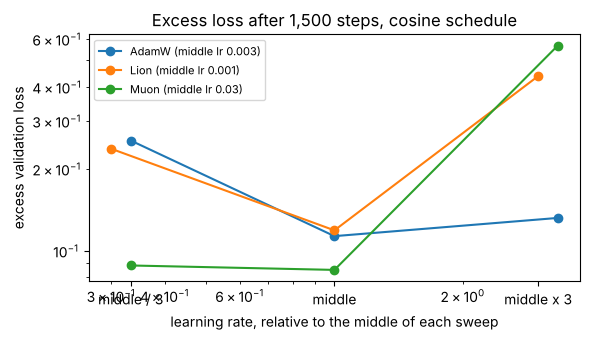

In [8]:
def lion(lr):
    def make(model):
        opt = Lion(model.parameters(), lr=lr)
        for grp in opt.param_groups: grp["initial_lr"] = lr
        return [opt]
    return make


def muon(lr, other_lr=3e-3):
    def make(model):
        hidden = [model.fc1.weight, model.fc2.weight]                  # 2-D hidden-layer matrices
        rest = [p for p in model.parameters() if all(p is not h for h in hidden)]
        o1, o2 = Muon(hidden, lr=lr), torch.optim.AdamW(rest, lr=other_lr, weight_decay=0.0)
        for grp in o1.param_groups: grp["initial_lr"] = lr
        for grp in o2.param_groups: grp["initial_lr"] = other_lr
        return [o1, o2]
    return make


SWEEPS = {"AdamW": (adamw, [1e-3, 3e-3, 1e-2]), "Lion": (lion, [3e-4, 1e-3, 3e-3]), "Muon": (muon, [0.01, 0.03, 0.1])}
opt_results = {}
t0 = time.time()
for name, (factory, lrs) in SWEEPS.items():
    opt_results[name] = []
    for lr in lrs:
        _, hist, _ = train_lm(factory(lr), lambda s: schedule("cosine", s, TOTAL), TOTAL)
        opt_results[name].append(hist[-1])
    best = int(np.argmin(opt_results[name]))
    print(f"{name:6s} excess loss at lr {lrs}: " + ", ".join(f"{v:.4f}" for v in opt_results[name])
          + f"  -> best {opt_results[name][best]:.4f} at lr {lrs[best]:g}")
print(f"(nine runs took {time.time() - t0:.0f} s)")

plt.figure(figsize=(6, 3.5))
for name, (factory, lrs) in SWEEPS.items():
    lrs_rel = np.array(lrs) / lrs[1]                       # middle value of each sweep at 1
    plt.plot(lrs_rel, opt_results[name], "o-", label=f"{name} (middle lr {lrs[1]:g})")
plt.xscale("log"); plt.yscale("log")
plt.xticks([1 / 3, 1, 3], ["middle / 3", "middle", "middle x 3"])
plt.title("Excess loss after 1,500 steps, cosine schedule")
plt.xlabel("learning rate, relative to the middle of each sweep"); plt.ylabel("excess validation loss")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 6. Memory: what does it take to train a big model?
Before activations, training with Adam stores weights, gradients and two optimizer states (m and v). In mixed precision with fp32 master weights (Micikevicius et al. 2018) that is 2 + 2 + (4 + 4 + 4) = 16 bytes per parameter. ZeRO (Rajbhandari et al. 2020) splits these across N GPUs instead of copying them: stage 1 shards the optimizer states, stage 2 also the gradients, stage 3 also the weights (PyTorch's FSDP works like stage 3; Zhao et al. 2023).

In [9]:
def training_memory_gb(n_params, precision="mixed", zero_stage=0, n_gpus=1):
    """Memory per GPU for weights, gradients and Adam states, without activations (ZeRO paper's accounting)."""
    if precision == "fp32":
        weights, grads, optim = 4, 4, 8          # fp32 weights and gradients; Adam's m and v
    else:
        weights, grads, optim = 2, 2, 12         # fp16/bf16 weights and gradients; fp32 master weights, m and v
    if zero_stage >= 1: optim /= n_gpus
    if zero_stage >= 2: grads /= n_gpus
    if zero_stage >= 3: weights /= n_gpus
    return n_params * (weights + grads + optim) / 1e9

print(f"7B model, fp32 Adam:            {training_memory_gb(7e9, 'fp32'):6.1f} GB")
print(f"7B model, mixed precision Adam: {training_memory_gb(7e9):6.1f} GB  (same 16 bytes per parameter)")
for stage in [1, 2, 3]:
    print(f"7B model, ZeRO-{stage} over 8 GPUs:    {training_memory_gb(7e9, zero_stage=stage, n_gpus=8):6.1f} GB per GPU")
paper = [training_memory_gb(7.5e9, zero_stage=s, n_gpus=64) for s in [0, 1, 2, 3]]
print("check against the ZeRO paper (7.5B parameters, 64 GPUs): " + ", ".join(f"{m:.1f}" for m in paper) + " GB")

7B model, fp32 Adam:             112.0 GB
7B model, mixed precision Adam:  112.0 GB  (same 16 bytes per parameter)
7B model, ZeRO-1 over 8 GPUs:      38.5 GB per GPU
7B model, ZeRO-2 over 8 GPUs:      26.2 GB per GPU
7B model, ZeRO-3 over 8 GPUs:      14.0 GB per GPU
check against the ZeRO paper (7.5B parameters, 64 GPUs): 120.0, 31.4, 16.6, 1.9 GB


**Activation checkpointing** (Chen et al. 2016) stores only some layer inputs on the forward pass and recomputes the rest during the backward pass: less memory for extra compute. We measure memory by counting the bytes of every tensor that autograd saves for the backward pass, and compute by counting forward calls of the linear layers (wall-clock time on a shared CPU is too noisy to trust).

In [10]:
from torch.utils.checkpoint import checkpoint_sequential

torch.manual_seed(0)
deep = nn.Sequential(*[nn.Sequential(nn.Linear(256, 256), nn.GELU()) for _ in range(16)])
x_big = torch.randn(1024, 256)
calls = [0]
for block in deep:
    block[0].register_forward_hook(lambda mod, inp, out: calls.__setitem__(0, calls[0] + 1))

def forward_backward(use_checkpoint):
    deep.zero_grad(set_to_none=True)
    calls[0], saved = 0, [0]
    def pack(t):
        saved[0] += t.numel() * t.element_size()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        out = checkpoint_sequential(deep, 4, x_big, use_reentrant=False) if use_checkpoint else deep(x_big)
    out.pow(2).mean().backward()
    return saved[0] / 2 ** 20, calls[0], [p.grad.clone() for p in deep.parameters()]

mb0, calls0, grads0 = forward_backward(False)
mb1, calls1, grads1 = forward_backward(True)
diff = max((a - b).abs().max().item() for a, b in zip(grads0, grads1))
print(f"no checkpointing:              {mb0:5.1f} MB saved for backward, {calls0} linear-layer forward calls")
print(f"checkpointing (4 segments):    {mb1:5.1f} MB saved for backward, {calls1} linear-layer forward calls")
print(f"largest difference between the two sets of gradients: {diff:.1e}")

no checkpointing:               35.8 MB saved for backward, 16 linear-layer forward calls
checkpointing (4 segments):     12.0 MB saved for backward, 28 linear-layer forward calls
largest difference between the two sets of gradients: 0.0e+00


### 7. Measuring real GPU memory (NOT RUN here)

In [ ]:
# NOT RUN: needs a CUDA GPU (CPU memory cannot be measured this way).
import torch, torch.nn as nn
from torch.utils.checkpoint import checkpoint_sequential

model = nn.Sequential(*[nn.Sequential(nn.Linear(4096, 4096), nn.GELU()) for _ in range(24)]).cuda()
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
x = torch.randn(8192, 4096, device="cuda")
for use_ckpt in [False, True]:
    for use_bf16 in [False, True]:
        torch.cuda.reset_peak_memory_stats()
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=use_bf16):
            out = checkpoint_sequential(model, 4, x, use_reentrant=False) if use_ckpt else model(x)
            loss = out.float().pow(2).mean()
        loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
        print(f"checkpointing={use_ckpt}, bf16 autocast={use_bf16}: "
              f"peak {torch.cuda.max_memory_allocated() / 2**30:.2f} GiB")
# Compare the peaks with training_memory_gb (weights + gradients + Adam states) to see how much is activations.

### TODO
1. Add a fourth schedule to section 4, 'linear decay to zero from the start (after warmup)', and compare its final excess loss with cosine and WSD.
2. Give Lion decoupled weight decay (try 3 to 10 times AdamW's value) and AdamW weight decay 0.1 in section 5. Does the ranking change?
3. Complete the function below.

In [11]:
# TODO: the smallest number of 80 GB GPUs that holds a 70B model's weights, gradients and Adam states with ZeRO-3.
def min_gpus_zero3(n_params, gpu_gb=80):
    return None      # replace: smallest n with training_memory_gb(n_params, zero_stage=3, n_gpus=n) <= gpu_gb

answer = min_gpus_zero3(70e9)
print("not done yet" if answer is None else f"a 70B model needs at least {answer} GPUs of 80 GB, before activations")

not done yet


### What to notice
- **L2 versus decoupled decay (section 2).** In the two-weight toy, Adam + L2 left the weight with large gradients at 0.882 and drove the weight with no gradient to 0.000. AdamW shrank both by about the same factor (0.541 and 0.606; pure decay gives 0.606). On digits the same nominal λ meant very different things: λ = 1 destroyed the Adam + L2 network (test accuracy 0.101, weight norm 0.0), while AdamW kept 0.948. AdamW with λ up to 0.1 changed almost nothing (0.940), because with learning rate 1e-3 and 600 steps the total shrinkage is small (lr × λ × steps = 0.06 at λ = 0.1).
- **No generalization win for AdamW here.** The best accuracies were similar: Adam + L2 0.960 at λ = 1e-3 and AdamW 0.948 at λ = 1. Loshchilov & Hutter's evidence came from deeper image networks, and their other main finding is that AdamW's best λ depends less on the learning rate; this toy does not test that.
- **Warmup (section 3).** Warmup helped at all three peak learning rates (0.912 to 0.919, 0.905 to 0.932, and 0.191 to 0.555), most at the highest one. At 0.1 training was still poor with warmup: warmup widens the range of usable learning rates; it does not make every learning rate safe.
- **Schedules (section 4).** Constant learning rate ended at an excess loss of 0.170, cosine at 0.113 and WSD at 0.116. WSD follows the constant run until its decay starts at step 1,200, then drops quickly to cosine's level. A 150-step decay branched from WSD's step-600 checkpoint reached 0.191, better than a cosine run planned for 750 steps (0.219).
- **Optimizers (section 5).** With a three-point learning-rate sweep each, Muon reached 0.085, AdamW 0.113 and Lion 0.119. Lion's best learning rate (1e-3) was 3 times smaller than AdamW's (3e-3), in line with the Lion paper's advice. The comparison is per step: each Muon step also runs five Newton–Schulz iterations, whose cost grows with the matrix size, not the batch, so on this tiny model Muon runs were noticeably slower.
- **Memory (section 6).** At 16 bytes per parameter a 7B model needs 112 GB before activations, with or without mixed precision; ZeRO-3 over 8 GPUs brings that to 14 GB per GPU. The calculator reproduces the ZeRO paper's example (120, 31.4, 16.6 and 1.9 GB). Checkpointing cut the saved activations from 35.8 MB to 12.0 MB for 12 extra layer evaluations (28 instead of 16), with identical gradients.
- **Limits.** One seed per setting, tiny models, at most 1,500 steps. The papers' claims are about large models and long runs; rerun with several seeds before you trust a small gap.